# *Challenge 1*: A **kernel** methods / **DL** pipeline for the FashionMNIST dataset

Advanced Topics in Machine Learning -- Fall 2023, UniTS

<a target="_blank" href="https://colab.research.google.com/github/ganselmif/adv-ml-units/blob/main/notebooks/AdvML_Challenge_1.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>


During this first *challenge* of the *Advanced Machine Learning Course*, you will experiment with the development of a data analysis pipeline based upon various techniques seen during the lectures so far: some **unsupervised** (*e.g.* *PCA*, *kernel-PCA*) and some others **supervised** (*e.g.* *kernel SVM* and *Artificial Neural Networks* for classification).

### The dataset

The dataset of interest for the *challenge* will be [*FashionMNIST*](https://github.com/zalandoresearch/fashion-mnist), an *MNIST*-like dataset of grayscale images of fashion items. Originally developed by Zalando Research in 2017 as a harder (yet *drop-in* compatible) replacement for the original *MNIST* dataset, it has been used in several papers and competitions since then.

Remember to consider the *dataset* mentioned below as the **training set** offered by *FashionMNIST*. Use the *test set* only at the end, to evaluate the overall accuracy of the pipeline!

### Section 1: Understanding data geometry

Load the dataset in the most suitable form for the tasks that follow. Then, perform the following steps, with the goal of developing a geometric understanding of the dataset:

1. Perform a (linear) *PCA* on the dataset, and plot the first two (or three!) principal components along with the true label. Comment on data separation.

2. Perform a *kernel-PCA* on the dataset with a Gaussian kernel, and plot the first two (or three!) principal components along with the true label. Try to tune the dispersion parameter of the kernel to obtain a good separation of the data. Comment.

3. Perform another *kernel-PCA* on the dataset with another kernel of your own choice, and plot the first two (or three!) principal components along with the true label. Try to tune the degree of the polynomial kernel to obtain a good separation of the data. Comment.

Whenever suitable, try to complement your analysis with some graphs!

**IMPORTANT NOTICE**: As some of you have reported, performing *kernel PCA* on the entire *FashionMNIST* dataset can be memory- and time- demanding (as it scales with the square of the number of datapoints!). In case you want to reduce such requirements, you can either:
  - Reduce the number of datapoints on which to perform *kPCA*, *e.g.* by slicing the randomly-shuffled dataset *(most effective!)*;
  - Reduce the size of the images in the dataset (*i.e.* by dropping even/odd rows/columns, or performing local pooling) *(somehow effective: you may want to try it if you do not have access to powerful compute, but still enjoy challenges!)*.

In [145]:
from torchvision import datasets
from torchvision import transforms

from sklearn.decomposition import PCA, KernelPCA
from sklearn.preprocessing import StandardScaler

from matplotlib import pyplot as plt

import numpy as np

In [146]:
train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transforms.ToTensor(), download=True)
test_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transforms.ToTensor(), download=True)

X_train, y_train = train_dataset.data.numpy(), train_dataset.targets.numpy()
X_test, y_test = test_dataset.data.numpy(), test_dataset.targets.numpy()

In [147]:
n_samples = 6000
np.random.seed(37)
indices = np.random.choice(len(X_train), size=n_samples, replace=False)

X_train = X_train[indices]
y_train = y_train[indices]

In [148]:
if len(X_train.shape) == 3:
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1]*X_train.shape[2])
if len(X_test.shape) == 3:
    X_test = X_test.reshape(X_test.shape[0], X_test.shape[1]*X_test.shape[2])

In [149]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [150]:
pca = PCA(n_components=10)
rbf_pca = KernelPCA(n_components=10, kernel="rbf")
poly_pca = KernelPCA(n_components=10, kernel="poly")
cos_pca = KernelPCA(n_components=10, kernel="cosine", gamma=0.01)

X_test_pca = pca.fit(X_train).transform(X_test)
X_test_kernel_pca = rbf_pca.fit(X_train).transform(X_test)
X_test_poly_pca = poly_pca.fit(X_train).transform(X_test)
X_test_cos_pca = cos_pca.fit(X_train).transform(X_test)

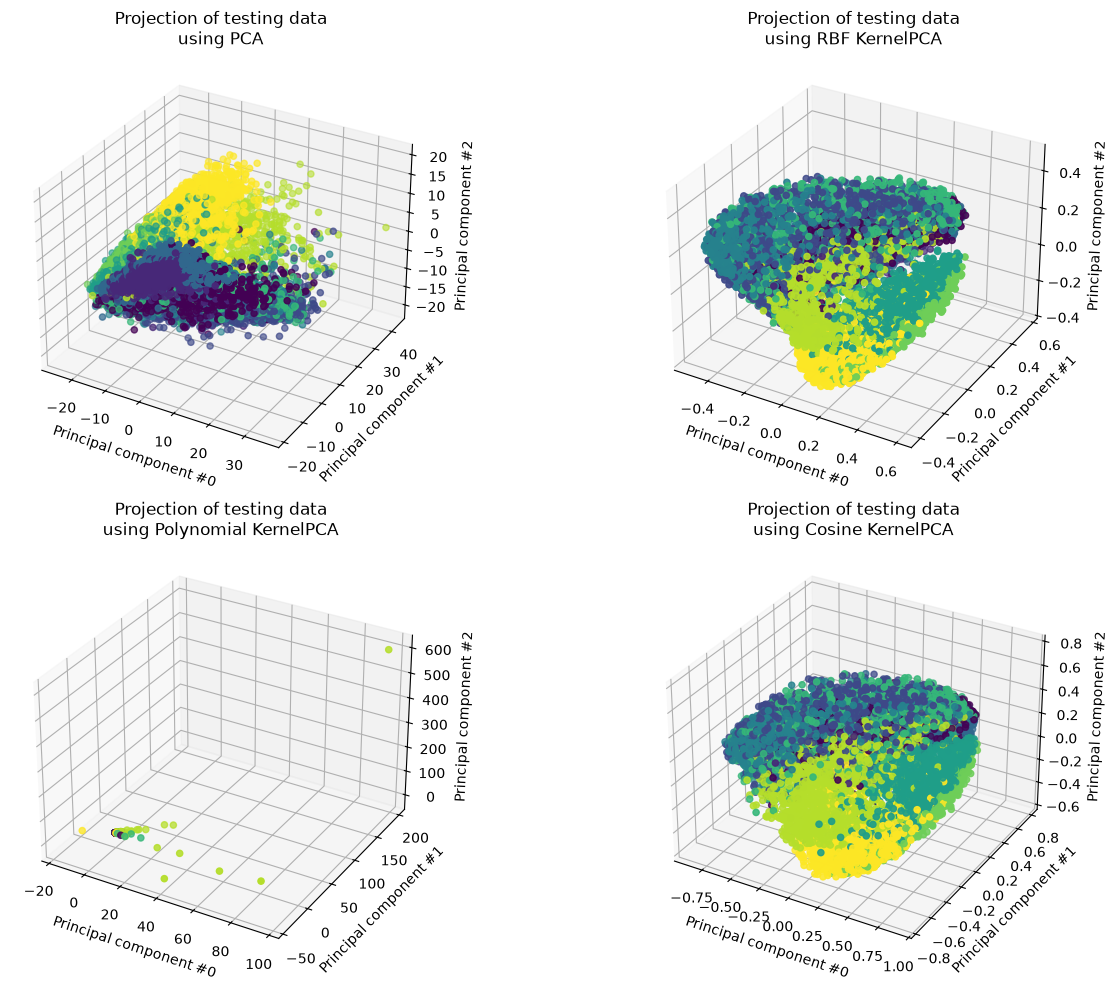

In [151]:
fig = plt.figure(figsize=(14, 10))

pca_ax = fig.add_subplot(2, 2, 1, projection='3d')
kernel_pca_ax = fig.add_subplot(2, 2, 2, projection='3d')
poly_pca_ax = fig.add_subplot(2, 2, 3, projection='3d')
cos_pca_ax = fig.add_subplot(2, 2, 4, projection='3d')

pca_ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1], X_test_pca[:, 2], c=y_test)
pca_ax.set_zlabel("Principal component #2")
pca_ax.set_ylabel("Principal component #1")
pca_ax.set_xlabel("Principal component #0")
pca_ax.set_title("Projection of testing data\nusing PCA")

kernel_pca_ax.scatter(X_test_kernel_pca[:, 0], X_test_kernel_pca[:, 1], X_test_kernel_pca[:, 2], c=y_test)
kernel_pca_ax.set_zlabel("Principal component #2")
kernel_pca_ax.set_ylabel("Principal component #1")
kernel_pca_ax.set_xlabel("Principal component #0")
kernel_pca_ax.set_title("Projection of testing data\nusing RBF KernelPCA")

poly_pca_ax.scatter(X_test_poly_pca[:, 0], X_test_poly_pca[:, 1], X_test_poly_pca[:, 2], c=y_test)
poly_pca_ax.set_zlabel("Principal component #2")
poly_pca_ax.set_ylabel("Principal component #1")
poly_pca_ax.set_xlabel("Principal component #0")
poly_pca_ax.set_title("Projection of testing data\nusing Polynomial KernelPCA")

cos_pca_ax.scatter(X_test_cos_pca[:, 0], X_test_cos_pca[:, 1], X_test_cos_pca[:, 2], c=y_test)
cos_pca_ax.set_zlabel("Principal component #2")
cos_pca_ax.set_ylabel("Principal component #1")
cos_pca_ax.set_xlabel("Principal component #0")
cos_pca_ax.set_title("Projection of testing data\nusing Cosine KernelPCA")

plt.tight_layout()
plt.show()

In [152]:
pca_variance = pca.explained_variance_ratio_
rbf_variance = rbf_pca.eigenvalues_ / np.sum(rbf_pca.eigenvalues_)
poly_variance = poly_pca.eigenvalues_ / np.sum(poly_pca.eigenvalues_)
cos_variance = cos_pca.eigenvalues_ / np.sum(cos_pca.eigenvalues_)

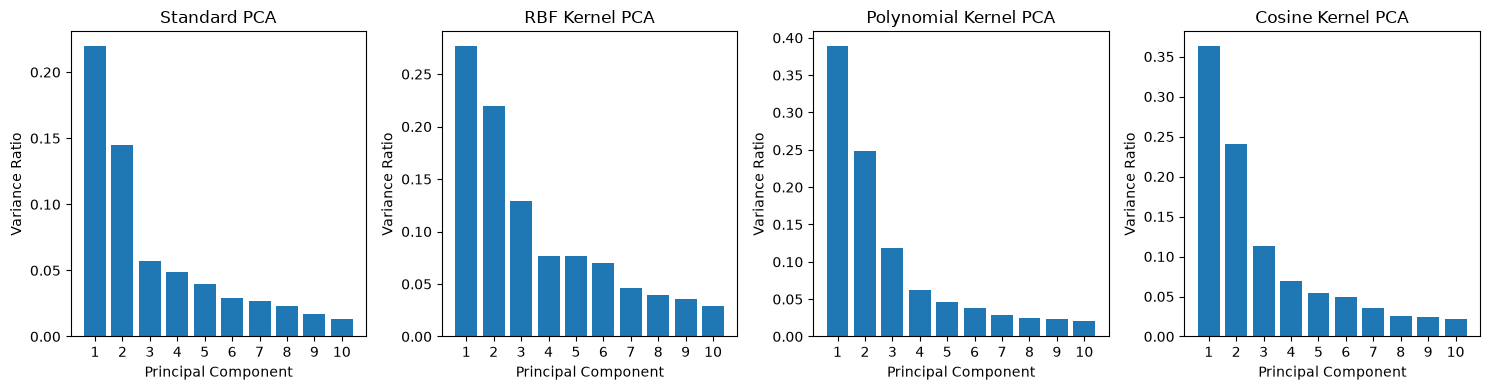

In [153]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

models = [
    ("Standard PCA", pca_variance),
    ("RBF Kernel PCA", rbf_variance),
    ("Polynomial Kernel PCA", poly_variance),
    ("Cosine Kernel PCA", cos_variance)
]

for ax, (name, variance) in zip(axes, models):
    ax.bar(range(1, len(variance) + 1), variance)
    ax.set_title(name)
    ax.set_xlabel("Principal Component")
    ax.set_ylabel("Variance Ratio")
    ax.set_xticks(range(1, len(variance) + 1))

plt.tight_layout()
plt.show()

### Section 2: Bridging *unsupervised* and *supervised*

Choose one of the results obtained in the previous section (you should choose the one better explaining data geometry), and ignore the true labels. Then, perform the following steps:

1. Considering only the first $10$ components of the *(kernel-)PCA* and try to assign $10$ labels to the resulting datapoints. Choose the approach you deem most suitable. Comment on the results, by considering:
    
    a. How well does the label-assignment just performed reflect the true labels?

    b. Does the number of components used ($10$) reflect the actual *knee-* or *gap-* *point* of the spectrum associated to the principal components?

Whenever suitable, try to complement your analysis with some graphs!

In [154]:
from sklearn.cluster import KMeans
from sklearn.metrics import rand_score, completeness_score

model = KMeans(n_clusters=10, random_state=37)
target = model.fit(X_test_kernel_pca)

rs = rand_score(y_test, model.labels_)
print(rs)

cs = completeness_score(y_test, model.labels_)
print(cs)

0.8821634163416342
0.49672900497278105


In [155]:
from sklearn.metrics import accuracy_score

# assign a label based on the majority of a given classes within a cluster
possible_labels = [i for i in range (0, 9)]
assigned_labels = []
predictions = np.zeros_like(y_test)

for label in possible_labels:

    indices = model.labels_ == label # find all the indices of the points within a cluster
    true_label = y_test[indices] # find the true label of those points

    values, counts = np.unique(true_label, return_counts=True) # count the occurrency of a given 

    """for c, v in sorted(zip(counts, values), reverse=True):
        print(f"Value {v} : {c} occurrencies")
    print()"""

    max_index = np.argmax(counts)
    most_frequent_value = values[max_index]
    highest_count = counts[max_index]

    predictions[indices] = most_frequent_value

accuracy_score(y_test, predictions)

test_label_3 = predictions

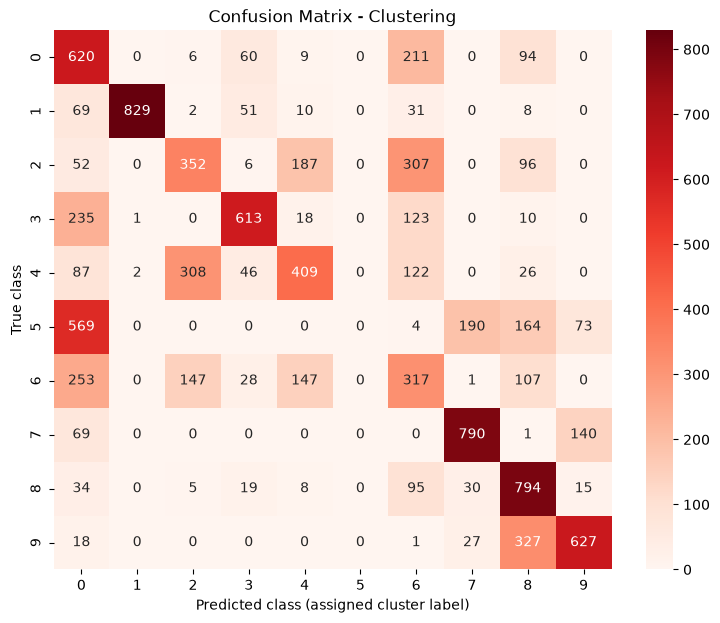

In [156]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=np.unique(y_test),
    yticklabels=np.unique(y_test)
)

plt.xlabel("Predicted class (assigned cluster label)")
plt.ylabel("True class")
plt.title("Confusion Matrix - Clustering")
plt.show()

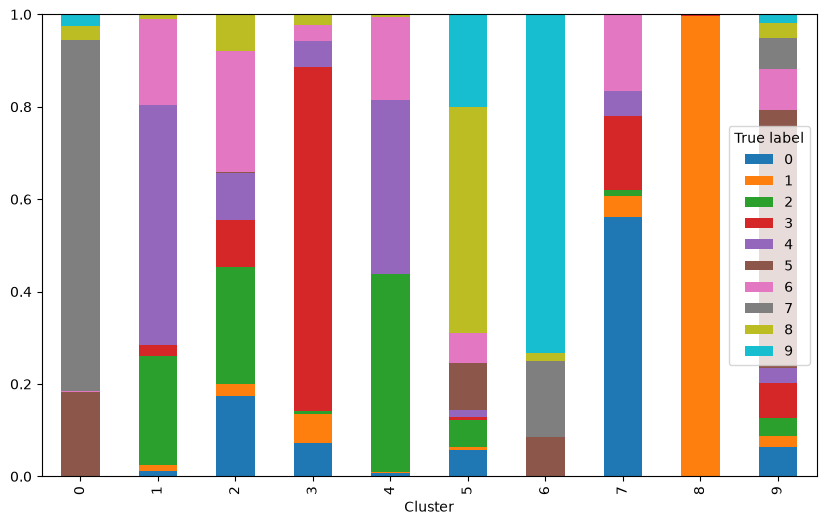

In [157]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Cluster": model.labels_,
    "True label": y_test
})

distribution = pd.crosstab(
    df["Cluster"],
    df["True label"],
    normalize="index"
)

distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="tab10",
    legend=True
)

plt.show()

### Section 3: (Supervised) classification

Consider the dataset composed of the original images, with the label assigned in the previous section (regardless of its actual match with the true label!). Then, define and learn a classifier that can predict the label of a new image. Specifically:

1. Learn a *kernel-SVM* on the data/label pairs. The choice of the kernel and its hyperparameters is up to your experimentation and time availability. Comment on your choices and results.

2. Learn a *fully-connected NN* on the data/label pairs. The choice of the architecture and its hyperparameters is up to your experimentation and time availability: show at least two different hyperparameter configurations, and comment on the results.

3. Learn a *CNN* on the data/label pairs. The choice of the architecture and its hyperparameters is up to your experimentation and time availability. Comment on the results with special respect to the FCN architecture.

In [158]:
model = KMeans(n_clusters=10, random_state=37)
target = model.fit(rbf_pca.transform(X_train))

# assign a label based on the majority of a given classes within a cluster
possible_labels = [i for i in range (0, 9)]
assigned_labels = []
true_label_3 = np.zeros_like(y_train)

for label in possible_labels:

    indices = model.labels_ == label # find all the indices of the points within a cluster
    true_label = y_train[indices] # find the true label of those points

    values, counts = np.unique(true_label, return_counts=True) # count the occurrency of a given 

    """for c, v in sorted(zip(counts, values), reverse=True):
        print(f"Value {v} : {c} occurrencies")
    print()"""

    max_index = np.argmax(counts)
    most_frequent_value = values[max_index]
    highest_count = counts[max_index]

    true_label_3[indices] = most_frequent_value
    
accuracy_score(y_train, true_label_3)

0.5211666666666667

In [159]:
from sklearn.svm import SVC

model = SVC(kernel="rbf", decision_function_shape="ovr")
model.fit(X_train, true_label_3)
y_pred = model.predict(X_test)

In [160]:
print("One-vs-One Accuracy:", accuracy_score(predictions, y_pred))

One-vs-One Accuracy: 0.6114


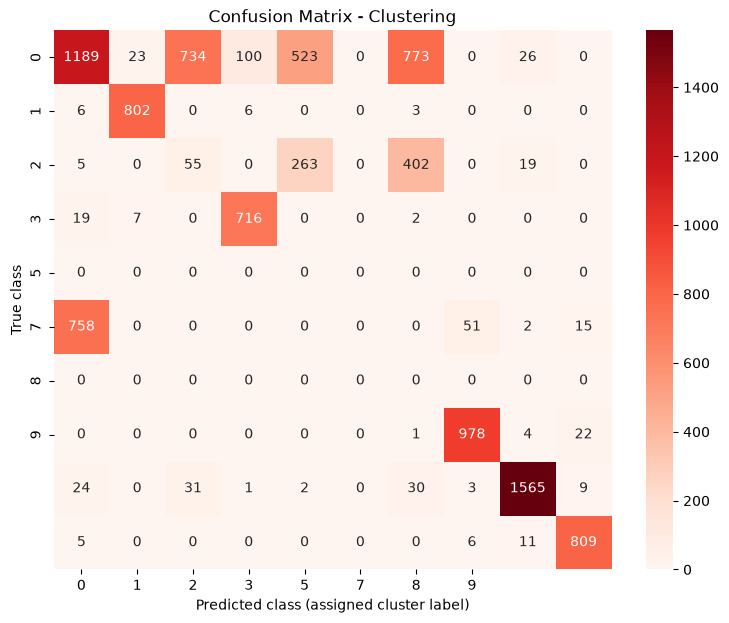

In [162]:
cm = confusion_matrix(y_pred, test_label_3)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=np.unique(true_label_3),
    yticklabels=np.unique(true_label_3)
)

plt.xlabel("Predicted class (assigned cluster label)")
plt.ylabel("True class")
plt.title("Confusion Matrix - Clustering")
plt.show()

### Section 4: Wrap-up!

Evaluate the overall accuracy of the pipeline on the *test set* of *FashionMNIST*. *I.e.* compare the predicted labels from the three classifiers built in *Section 3* with the true labels.

In order to assign a true label *name* (e.g. *trousers*, *sandal*, ...) to those determined just from *(kernel-)PCA* (that obviously carry no direct information about the subject of the picture), you can either:

i. *Cheat* and use the most abundant labels for each group of *(kernel-)PCA-labelled* datapoints.

ii. Sample a subset of datapoints from each *(kernel-)PCA-labelled* class, and assign one label by direct visual inspection. If you choose this route, it may also serve as a reminder of the fact that *expert labelling* is not always a trivial (and almost never a fast) task!

Comment on the results obtained.

### Section 5: A *fully-supervised* approach

Repeat the steps of *Section 3* using the true labels of the dataset. Comment on the results, and draw a comparison between such results and those obtained from the previous *hybrid* pipeline.


And please, avoid doing that... 👇🏻

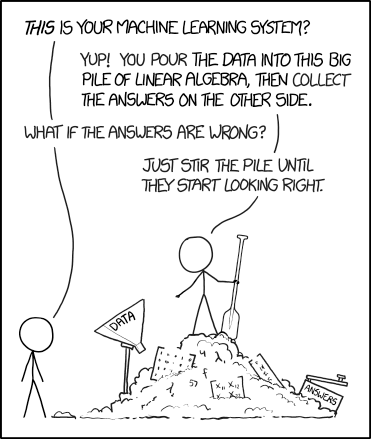